In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

import os

In [5]:
base_path = r"G:\12 Semester\CVPR\MID\CNN_Project\dataset\New Plant Diseases Dataset(Augmented)"

train_dir = base_path + r"\train"
val_dir   = base_path + r"\valid"
test_dir  = base_path + r"\valid"   # (use valid as test if no test folder)

In [7]:
from tqdm import tqdm

In [8]:
train_transform = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor()
])

In [9]:
train_data = datasets.ImageFolder(train_dir, transform=train_transform)
val_data   = datasets.ImageFolder(val_dir, transform=val_transform)
test_data  = datasets.ImageFolder(test_dir, transform=val_transform)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_data, batch_size=32, shuffle=False)
test_loader  = DataLoader(test_data, batch_size=32, shuffle=False)

class_names = train_data.classes
print("Classes:", class_names)

Classes: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']


In [10]:
class CNN(nn.Module):
    def __init__(self, num_classes):
        super(CNN, self).__init__()
        
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*16*16, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.conv(x)
        x = self.fc(x)
        return x

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = CNN(num_classes=len(class_names)).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

In [12]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)

scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

In [13]:
train_losses = []
val_losses = []
train_acc = []
val_acc = []

In [15]:
train_losses, val_losses = [], []
train_acc, val_acc = [], []

epochs = 10

for epoch in range(epochs):
    print(f"\nEpoch {epoch+1}/{epochs}")
    
    # 🔹 TRAINING
    model.train()
    running_loss, correct = 0, 0
    
    loop = tqdm(train_loader, desc="Training", leave=False)
    
    for images, labels in loop:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        
        # 🔥 Update progress bar
        loop.set_postfix(loss=loss.item())
    
    acc = correct / len(train_data)
    
    # 🔹 VALIDATION
    model.eval()
    val_loss, val_correct = 0, 0
    
    val_loop = tqdm(val_loader, desc="Validation", leave=False)
    
    with torch.no_grad():
        for images, labels in val_loop:
            images, labels = images.to(device), labels.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            
            val_loop.set_postfix(val_loss=loss.item())
    
    val_accuracy = val_correct / len(val_data)
    
    train_losses.append(running_loss)
    val_losses.append(val_loss)
    train_acc.append(acc)
    val_acc.append(val_accuracy)
    
    scheduler.step()
    
    print(f"Train Acc: {acc:.4f} | Val Acc: {val_accuracy:.4f}")


Epoch 1/10


Train Acc: 0.5560 | Val Acc: 0.5823

Epoch 2/10


Train Acc: 0.6666 | Val Acc: 0.5887

Epoch 3/10


Train Acc: 0.7059 | Val Acc: 0.7514

Epoch 4/10


Train Acc: 0.7562 | Val Acc: 0.6031

Epoch 5/10


...

Train Acc: 0.8248 | Val Acc: 0.8347

Epoch 7/10


Train Acc: 0.8333 | Val Acc: 0.8676

Epoch 8/10


Train Acc: 0.8454 | Val Acc: 0.7937

Epoch 9/10


Train Acc: 0.8548 | Val Acc: 0.8458

Epoch 10/10


Train Acc: 0.8601 | Val Acc: 0.8685


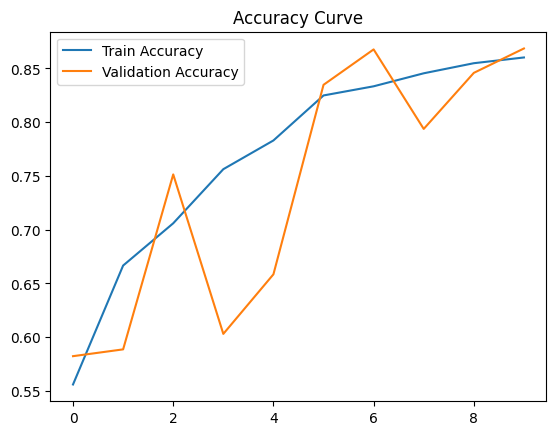

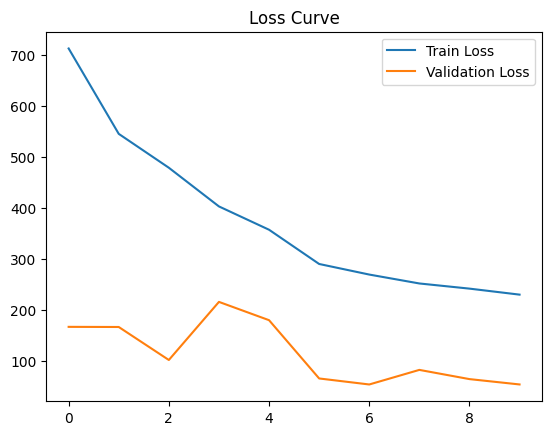

In [16]:
plt.plot(train_acc, label="Train Accuracy")
plt.plot(val_acc, label="Validation Accuracy")
plt.legend()
plt.title("Accuracy Curve")
plt.show()

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.legend()
plt.title("Loss Curve")
plt.show()

In [17]:
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

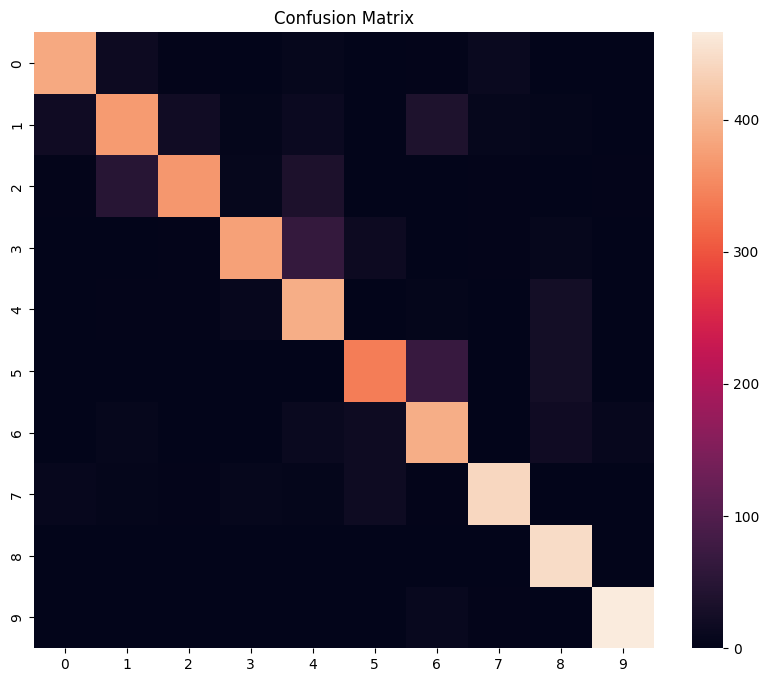

In [18]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=False)
plt.title("Confusion Matrix")
plt.show()

In [19]:
print(classification_report(all_labels, all_preds, target_names=class_names))

                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.93      0.91      0.92       425
                        Tomato___Early_blight       0.83      0.77      0.80       480
                         Tomato___Late_blight       0.92      0.79      0.85       463
                           Tomato___Leaf_Mold       0.93      0.80      0.86       470
                  Tomato___Septoria_leaf_spot       0.74      0.90      0.81       436
Tomato___Spider_mites Two-spotted_spider_mite       0.87      0.78      0.82       435
                         Tomato___Target_Spot       0.76      0.86      0.80       457
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.94      0.90      0.92       490
                 Tomato___Tomato_mosaic_virus       0.85      1.00      0.92       448
                             Tomato___healthy       0.97      0.97      0.97       481

                                     accu

In [20]:
torch.save(model.state_dict(), "cnn_model.pth")

In [21]:
print(model)

CNN(
  (conv): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)
